# Variational Monte Carlo in continuous space
## Stage 1 — Noninteracting trapped spin-1/2 fermions in 2D

**Solution notebook.** This exercise extends the previous 1D boson / spinless-fermion notebook to fixed populations $N_\uparrow,N_\downarrow$ in a 2D isotropic harmonic trap. The numerical architecture is deliberately similar: **ansatz $\to$ Metropolis $\to$ local energy $\to$ blocking $\to$ observables and benchmarks**.

We use $\hbar=m=\omega=1$, particle coordinates $\mathbf r_i=(x_i,y_i)$, and **no interactions**. Particles are ordered with all spin-up coordinates first, then spin-down coordinates.

**Learning outcomes:** derive oscillator shells and energies; build exact 2D orbitals and their derivatives; factorize a fixed-spin Slater determinant; preserve sign separately from $\log|\Psi|$; sample $|\Psi|^2$; verify energies, radial density, exchange holes, and antisymmetry.

> Dependency: NumPy, SciPy, Matplotlib. The automatic-differentiation cross-check uses JAX if available; enable float64 for near-machine-precision checks.

## 1. Physics: 2D oscillator, shell filling and fixed-spin antisymmetry

A single-particle Hamiltonian separates into $x$ and $y$ components,

$$h=-\tfrac12(\partial_x^2+\partial_y^2)+\tfrac12(x^2+y^2).$$

Its eigenfunctions are $\phi_{n_xn_y}(x,y)=\varphi_{n_x}(x)\varphi_{n_y}(y)$ and eigenvalues are

$$\boxed{\epsilon_{n_x,n_y}=n_x+n_y+1.}$$

Shell $s=n_x+n_y$ has $g_s=s+1$ **spatial** orbitals. Every spatial orbital may hold one up-spin and one down-spin fermion. The fully filled shells with $s=0,\ldots,q-1$ hold $q(q+1)/2$ particles **per spin**, so spin-balanced closed-shell total numbers are $N=2,6,12,20,\ldots$.

For $N_\sigma=q(q+1)/2+r$ with $0\le r\le q$,

$$E_0(N_\sigma)=\sum_{s=0}^{q-1}(s+1)^2+r(q+1),\qquad
E_0(N_\uparrow,N_\downarrow)=E_0(N_\uparrow)+E_0(N_\downarrow).$$

**Why two determinants?** A fully antisymmetric determinant built from spin-orbitals becomes block diagonal in a fixed spin-ordering sector because $\langle\uparrow|\downarrow\rangle=0$. Hence its spatial amplitude (up to an irrelevant global constant) is

$$\boxed{\Psi(X)=D_\uparrow(X_\uparrow)D_\downarrow(X_\downarrow)}.$$

Swapping **one pair** of same-spin coordinates swaps exactly two rows of one determinant and flips the sign of $\Psi$. Swapping one up and one down requires also swapping their spin labels in the **full** spin-coordinate wavefunction; it is not tested by swapping spatial rows across the two fixed spin blocks. Swapping a pair in **each** block is two transpositions and yields a plus sign.

The choices $1+1$, $2+2$, $3+3$ have exact energies **2, 6, 10**. The $2+2$ system has an **open, degenerate spatial shell**: choosing $\phi_{10}$ rather than $\phi_{01}$ gives a valid (anisotropic) ground state.

## 2. Imports, numerical conventions and exact shell occupations

Keep the same plotting and random-generator conventions as the earlier notebook. Configurations have shape `(n_samples, N, 2)`, where the last axis holds `(x,y)`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial
from scipy.special import eval_hermite

rng = np.random.default_rng(1234)
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9",
    "axes.axisbelow": True, "lines.linewidth": 2
})
C_VMC, C_EXACT, C_REF = "#2a78d6", "#eb6834", "#898781"
C_FERMI = "#1baf7a"

In [ ]:
def occupied_orbitals(n):
    """Lowest n spatial orbitals as [(n_x,n_y),...], ordered shell by shell.

    Within a shell use (s,0),(s-1,1),...,(0,s).
    The choice of basis within a partially filled shell is not unique.
    """
    labels = []
    s = 0
    while len(labels) < n:
        for nx in range(s, -1, -1):
            labels.append((nx, s-nx))
            if len(labels) == n:
                return labels
        s += 1
    return labels


def exact_energy(n_up, n_down):
    return sum(nx+ny+1 for nx,ny in occupied_orbitals(n_up)) + \
           sum(nx+ny+1 for nx,ny in occupied_orbitals(n_down))

for nu, nd in [(1,1), (2,2), (3,3), (6,6)]:
    print(f"N_up={nu}, N_down={nd} | orbitals={occupied_orbitals(nu)} | E0={exact_energy(nu,nd)}")
assert [exact_energy(n,n) for n in (1,2,3,6)] == [2,6,10,28]

N_up=1, N_down=1 | orbitals=[(0, 0)] | E0=2
N_up=2, N_down=2 | orbitals=[(0, 0), (1, 0)] | E0=6
N_up=3, N_down=3 | orbitals=[(0, 0), (1, 0), (0, 1)] | E0=10
N_up=6, N_down=6 | orbitals=[(0, 0), (1, 0), (0, 1), (2, 0), (1, 1), (0, 2)] | E0=28


## 3. Exact 2D oscillator orbitals and derivatives

Use normalized physicists' Hermite polynomials,

$$\varphi_n(x)=\frac{H_n(x)e^{-x^2/2}}{\pi^{1/4}\sqrt{2^n n\!}}.$$ 

For analytic derivatives, the ladder identity gives

$$\partial_x\phi_{n_xn_y}=\sqrt{2n_x}\,\phi_{n_x-1,n_y}-x\phi_{n_xn_y},$$

and analogously for $y$. The eigenvalue equation gives an efficient, independent Laplacian check,

$$\boxed{\nabla^2\phi_{n_xn_y}=(r^2-2\epsilon_{n_xn_y})\phi_{n_xn_y}}.$$

The output shapes should be `M = (..., n_orbitals)`, `dM = (..., n_orbitals, 2)`, `lapM = (..., n_orbitals)`. In a determinant matrix, the leading axes are `(n_samples, n_particles_of_that_spin)`.

In [3]:
def ho1d(x, n):
    return eval_hermite(n, x) * np.exp(-0.5*x**2) / (np.pi**0.25 * np.sqrt(2.0**n * factorial(n)))


def orbital_values(r, labels):
    x, y = r[..., 0], r[..., 1]
    return np.stack([ho1d(x, nx)*ho1d(y, ny) for nx,ny in labels], axis=-1)


def orbital_values_grad_lap(r, labels):
    x, y = r[..., 0], r[..., 1]
    M = orbital_values(r, labels)
    dx, dy = [], []
    for k, (nx, ny) in enumerate(labels):
        lower_x = np.sqrt(2*nx)*ho1d(x,nx-1)*ho1d(y,ny) if nx else 0.0
        lower_y = np.sqrt(2*ny)*ho1d(x,nx)*ho1d(y,ny-1) if ny else 0.0
        dx.append(lower_x-x*M[...,k])
        dy.append(lower_y-y*M[...,k])
    dM = np.stack([np.stack(dx, axis=-1), np.stack(dy, axis=-1)], axis=-1)
    energies = np.array([nx+ny+1 for nx,ny in labels])
    lapM = (np.sum(r**2, axis=-1)[...,None]-2*energies)*M
    return M, dM, lapM

# Elementary exact orbitals: phi_00 = exp(-r²/2)/sqrt(pi),
# phi_10 = sqrt(2)*x*phi_00, phi_01 = sqrt(2)*y*phi_00.
r_check = rng.normal(size=(12, 2))
M_check = orbital_values(r_check, occupied_orbitals(3))
phi00 = np.exp(-0.5*np.sum(r_check**2,axis=1))/np.sqrt(np.pi)
np.testing.assert_allclose(M_check[:,0], phi00)
np.testing.assert_allclose(M_check[:,1], np.sqrt(2)*r_check[:,0]*phi00)
np.testing.assert_allclose(M_check[:,2], np.sqrt(2)*r_check[:,1]*phi00)
print("Orbital values: elementary checks passed.")

Orbital values: elementary checks passed.


## 4. Spin-resolved Slater determinants, sign and log amplitude

For $\sigma\in\{\uparrow,\downarrow\}$, define $M_{ij}^\sigma=\phi_j(\mathbf r_i^\sigma)$. The real-space fixed-spin wavefunction is a product of two determinants:

$$\Psi=D_\uparrow D_\downarrow,\quad \operatorname{sgn}\Psi=\operatorname{sgn}D_\uparrow\operatorname{sgn}D_\downarrow,\quad \log|\Psi|=\log|D_\uparrow|+\log|D_\downarrow|.$$

**Never** use the ordinary real `log(det)` across fermionic nodes. Use `np.linalg.slogdet`, keep the sign separately, and sample with $2\log|\Psi|$. In a fixed spin block, the usual determinant normalization constants cancel in Metropolis ratios and local energies. A zero-size determinant is defined to be 1.

In [ ]:
def slater_sign_logabs(X, n_up):
    """Spin product: returns (sign,log|psi|) for X shape (samples,N,2)."""
    X = np.asarray(X)
    n = X.shape[1]
    sign = np.ones(len(X))
    logabs = np.zeros(len(X))
    for a,b in ((0,n_up), (n_up,n)):
        k = b-a
        if k == 0:
            continue
        M = orbital_values(X[:,a:b,:], occupied_orbitals(k))
        # we discussed this last time
        s,l = np.linalg.slogdet(M)
        sign *= s
        logabs += l
    return sign, logabs


def logabs_psi(X, n_up):
    return slater_sign_logabs(X, n_up)[1]

# Same-spin swap: one minus sign, no change in |psi|².
X_test = rng.normal(size=(20,6,2))
X_swapped = X_test.copy()
X_swapped[:,[0,1],:] = X_test[:,[1,0],:]
s1,l1 = slater_sign_logabs(X_test, 3)
s2,l2 = slater_sign_logabs(X_swapped, 3)
np.testing.assert_array_equal(s2, -s1)
np.testing.assert_allclose(l2, l1, atol=1e-12)
print("Same-spin exchange: sign flips and |psi|² is unchanged.")

Same-spin exchange: sign flips and |psi|² is unchanged.


## 5. Continuous-space Metropolis sampling (particle by particle)

Use your previous `metropolis_step` and `sample_mcmc` structure. A proposed step should move **one selected particle** by a vector $\boldsymbol\delta\in[-\Delta,\Delta]^2$. A sweep consists of $N$ such attempts. Sampling depends only on $\log|\Psi|$, not its sign.

$$A(X\to X')=\min\left(1,e^{2[\log|\Psi(X')|-\log|\Psi(X)|]}\right).$$

**Important shape change:** one configuration `(N,2)`, samples `(n_samples,N,2)`.

In [5]:
def metropolis_step(logpsi, x, logpsi_x, step_size, rng=rng):
    if logpsi_x is None:
        logpsi_x = logpsi(x[None,:,:])[0]
    index = rng.integers(x.shape[0])
    x_prime = x.copy()
    x_prime[index] += rng.uniform(-step_size, step_size, size=2)
    logpsi_prime = logpsi(x_prime[None,:,:])[0]
    log_accept = min(0.0, 2.0*(logpsi_prime-logpsi_x))
    if np.log(rng.random()) < log_accept:
        return x_prime, logpsi_prime, True
    return x, logpsi_x, False


def sample_mcmc(logpsi, n_particles, n_samples, n_discard, step_size,
                x0=None, rng=rng, return_acceptance=False):
    if x0 is None:
        x0 = rng.normal(size=(n_particles,2))
    x = np.array(x0, dtype=float, copy=True)
    logpsi_x = None
    n_accepted = 0
    samples = np.empty((n_samples,n_particles,2))
    for sweep in range(n_discard+n_samples):
        for _ in range(n_particles):
            x,logpsi_x,accepted = metropolis_step(logpsi,x,logpsi_x,step_size,rng)
            n_accepted += accepted
        if sweep >= n_discard:
            samples[sweep-n_discard] = x
    if return_acceptance:
        return samples, n_accepted/((n_discard+n_samples)*n_particles)
    return samples

# Small smoke test for the exact 2+2 wavefunction.
smoke, acceptance = sample_mcmc(lambda X: logabs_psi(X,2),
                                4, n_samples=250, n_discard=100,
                                step_size=1.0, return_acceptance=True)
assert smoke.shape == (250,4,2)
print("2+2 sampler: shape", smoke.shape, "acceptance", round(acceptance,3))

2+2 sampler: shape (250, 4, 2) acceptance 0.55


## 6. Local energy: derivatives of Slater determinants

As it was in the other problemset of the continous thing $L(X)=\log|\Psi(X)|$. Away from nodes,

$$E_L(X)=-\frac12\sum_i\left[\nabla_i^2L+|\nabla_i L|^2\right]+\frac12\sum_i r_i^2.$$

For a single spin Slater matrix $M$, changing particle $i$ only changes row $i$, so (summation over orbital index $j$)

$$\nabla_i L=\sum_j(M^{-1})_{ji}\,\nabla\phi_j(\mathbf r_i),$$

$$\nabla_i^2L=\sum_j(M^{-1})_{ji}\,\nabla^2\phi_j(\mathbf r_i)-|\nabla_iL|^2.$$

Equivalently, one can compute the local kinetic energy directly as $-\frac12\operatorname{tr}(M^{-1}L_M)$ where $(L_M)_{ij}=\nabla_i^2\phi_j(\mathbf r_i)$. This avoids explicitly forming second derivatives of a determinant. The two formulas must agree.

In [6]:
def grad_lap_logabs(X, n_up):
    """Return grad (samples,N,2), lap_logabs (samples,N)."""
    ns, N, _ = X.shape
    grad = np.zeros((ns,N,2))
    lap_logabs = np.zeros((ns,N))
    for a,b in ((0,n_up),(n_up,N)):
        k = b-a
        if k == 0:
            continue
        M,dM,lapM = orbital_values_grad_lap(X[:,a:b,:], occupied_orbitals(k))
        invM = np.linalg.inv(M)
        g = np.einsum('...ji,...ijc->...ic', invM, dM)
        lap_ratio = np.einsum('...ji,...ij->...i',invM,lapM)
        grad[:,a:b,:] = g
        lap_logabs[:,a:b] = lap_ratio - np.sum(g*g,axis=-1)
    return grad,lap_logabs


def local_energy_from_log_derivs(X, n_up):
    grad,lap = grad_lap_logabs(X,n_up)
    kinetic = -0.5*(np.sum(lap,axis=1)+np.sum(grad**2,axis=(1,2)))
    return kinetic + 0.5*np.sum(X**2,axis=(1,2))


def local_energy_matrix(X, n_up):
    """Independent analytic expression using orbital Laplacian matrices."""
    ns,N,_ = X.shape
    kinetic = np.zeros(ns)
    for a,b in ((0,n_up),(n_up,N)):
        k = b-a
        if k == 0:
            continue
        M,_,lapM = orbital_values_grad_lap(X[:,a:b,:],occupied_orbitals(k))
        kinetic -= 0.5*np.trace(np.linalg.solve(M,lapM),axis1=-2,axis2=-1)
    return kinetic + 0.5*np.sum(X**2,axis=(1,2))

X_check = rng.normal(size=(25,6,2))
e_log = local_energy_from_log_derivs(X_check,3)
e_mat = local_energy_matrix(X_check,3)
np.testing.assert_allclose(e_log,e_mat,atol=1e-10,rtol=1e-12)
np.testing.assert_allclose(e_mat,10.,atol=1e-10)
print("Energy, N=6: exact",exact_energy(3,3),
      "max |E_log-E_matrix| =",np.max(np.abs(e_log-e_mat)))

Energy, N=6: exact 10 max |E_log-E_matrix| = 2.7000623958883807e-13


## 7. Automatic differentiation cross-check (JAX)

The previous section used **analytic orbital derivatives**. We now independently differentiate the *actual determinant log amplitude* with JAX. For one configuration $X$ of shape `(N,2)`, `jax.grad` produces an `(N,2)` gradient and `jax.hessian` produces a `(N,2,N,2)` Hessian. Its diagonal contraction is $\sum_{i,\alpha}\partial^2 L/\partial x_{i\alpha}^2$.

We use the same shell occupation and normalized orbitals, but implement the small Hermite recursion with `jax.numpy` so the differentiation traces remain compatible with JAX. **This is an independent check**, not a replacement for the analytic derivative formulas. If JAX is unavailable, install `jax` and rerun this section.

In [7]:
try:
    import jax
    import jax.numpy as jnp
    jax.config.update('jax_enable_x64',True)
    HAS_JAX = True
except ImportError:
    HAS_JAX = False
    print('JAX unavailable: install jax to run this independent check.')

if HAS_JAX:
    def ho1d_jax(x,n):
        if n == 0:
            H = jnp.ones_like(x)
        elif n == 1:
            H = 2*x
        else:
            H0,H1 = jnp.ones_like(x),2*x
            for k in range(1,n):
                H0,H1 = H1,2*x*H1-2*k*H0
            H = H1
        return H*jnp.exp(-0.5*x*x)/(np.pi**0.25*np.sqrt(2.0**n*factorial(n)))

    def logabs_single_jax(X,n_up):
        L = 0.0
        for coords in (X[:n_up],X[n_up:]):
            k = coords.shape[0]
            if k:
                labels = occupied_orbitals(k)
                M = jnp.stack([ho1d_jax(coords[:,0],nx)*ho1d_jax(coords[:,1],ny)
                               for nx,ny in labels], axis=-1)
                L = L+jnp.linalg.slogdet(M)[1]
        return L

    def energy_ad_single(X,n_up):
        f = lambda Z: logabs_single_jax(Z,n_up)
        g = jax.grad(f)(X)
        H = jax.hessian(f)(X)
        return -0.5*(jnp.sum(g**2)+jnp.einsum('iaia->',H)) + 0.5*jnp.sum(X**2)

    # One configuration, 2+2: check derivatives numerically against analytic formulas.
    X_ad = rng.normal(size=(1,4,2))
    f = lambda Z: logabs_single_jax(Z,2)
    g_ad = np.asarray(jax.grad(f)(jnp.asarray(X_ad[0])))
    h_ad = np.asarray(jax.hessian(f)(jnp.asarray(X_ad[0])))
    g_analytic,lap_analytic = grad_lap_logabs(X_ad,2)
    np.testing.assert_allclose(g_ad,g_analytic[0],atol=1e-10)
    np.testing.assert_allclose(np.einsum('iaia->',h_ad),np.sum(lap_analytic[0]),atol=1e-10)
    e_ad = float(energy_ad_single(jnp.asarray(X_ad[0]),2))
    np.testing.assert_allclose(e_ad,local_energy_matrix(X_ad,2)[0],atol=1e-10)
    print(f'AD check: E_AD={e_ad:.12f}, E_exact={exact_energy(2,2)}; first/second derivatives agree.')

AD check: E_AD=6.000000000000, E_exact=6; first/second derivatives agree.


## 8. Energy benchmarks for $N=2,4,6$ and correlated-error estimation

For an exact eigenfunction, $E_L(X)=E_0$ **configuration by configuration**, except at the nodes where the log derivatives are singular. Thus the variance of the exact local energy is zero up to floating-point noise. Compare to shell-filling energies; there is **no ansatz optimization** in this noninteracting stage.

As in the earlier notebook, estimate uncertainty using means of successive blocks rather than pretending that each Metropolis configuration is independent. When all local energies are exactly constant, a tiny estimated error bar is simply roundoff, not an informative statistical precision limit.

1+1: VMC E=2.000000000000 ± 0 | exact=2 | acceptance=0.561 | max local deviation=4.4e-16


2+2: VMC E=6.000000000000 ± 0 | exact=6 | acceptance=0.512 | max local deviation=2.7e-15


3+3: VMC E=10.000000000000 ± 0 | exact=10 | acceptance=0.510 | max local deviation=3.6e-15


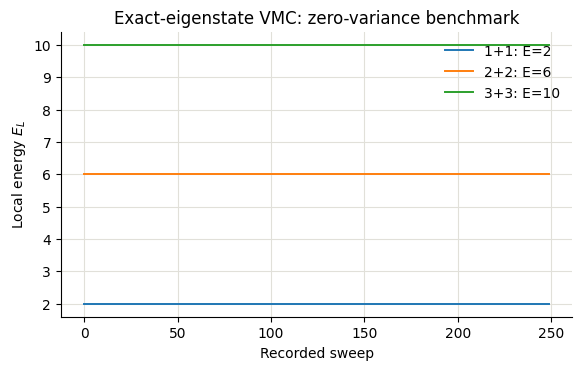

In [8]:
def estimate_energy(eloc, n_blocks=20):
    mean = np.mean(eloc)
    block_size = len(eloc)//n_blocks
    if block_size < 1:
        raise ValueError('Need at least n_blocks local-energy samples.')
    block_means = np.mean(eloc[:n_blocks*block_size].reshape(n_blocks,block_size),axis=1)
    err = np.std(block_means,ddof=1)/np.sqrt(n_blocks)
    return mean,err


def vmc_fermions(n_up,n_down,n_samples=2500,n_discard=400,step_size=1.1):
    logpsi = lambda X: logabs_psi(X,n_up)
    X,acceptance = sample_mcmc(logpsi,n_up+n_down,n_samples,n_discard,
                               step_size,return_acceptance=True)
    eloc = local_energy_matrix(X,n_up)
    energy,error = estimate_energy(eloc)
    return X,eloc,energy,error,acceptance

runs = {}
for nu,nd in [(1,1),(2,2),(3,3)]:
    X,eloc,e,err,accept = vmc_fermions(nu,nd,
                                         n_samples=5000 if nu==3 else 2500)
    runs[(nu,nd)] = X
    expected = exact_energy(nu,nd)
    print(f'{nu}+{nd}: VMC E={e:.12f} ± {err:.2g} | exact={expected} | '
          f'acceptance={accept:.3f} | max local deviation={np.max(np.abs(eloc-expected)):.2g}')
    assert np.abs(e-expected)<1e-10

fig,ax = plt.subplots(figsize=(6.6,3.7))
for (nu,nd),X in runs.items():
    e=local_energy_matrix(X,nu)
    ax.plot(np.arange(min(250,len(e))),e[:250],label=f'{nu}+{nd}: E={exact_energy(nu,nd)}',lw=1.4)
ax.set(xlabel='Recorded sweep',ylabel=r'Local energy $E_L$',title='Exact-eigenstate VMC: zero-variance benchmark')
ax.legend(frameon=False)
plt.show()

## 9. Radial number density: an explicit normalization convention

Define the **2D one-body number density** $n(\mathbf r)=\langle\sum_i\delta^{(2)}(\mathbf r-\mathbf r_i)\rangle$, with $\int d^2r\,n(\mathbf r)=N$. Its angular average is

$$n(r)=\frac1{2\pi}\int_0^{2\pi}n(r\cos\theta,r\sin\theta)\,d\theta,\qquad
\boxed{2\pi\int_0^\infty r\,n(r)\,dr=N.}$$

**Estimator:** divide the number of sampled coordinates in annulus $[r_k,r_{k+1})$ by $N_\mathrm{samples}\,\pi(r_{k+1}^2-r_k^2)$, **not** by just the annular width. Compare to the exact orbital sum $n_\mathrm{exact}(\mathbf r)=\sum_{\sigma,j\in\mathrm{occ}}|\phi_j(\mathbf r)|^2$. For $3+3$,

$$\boxed{n_{3+3}(r)=\frac2\pi e^{-r^2}(1+2r^2).}$$

For the open-shell $2+2$ state, the full 2D density is anisotropic but its angular average is still well-defined.

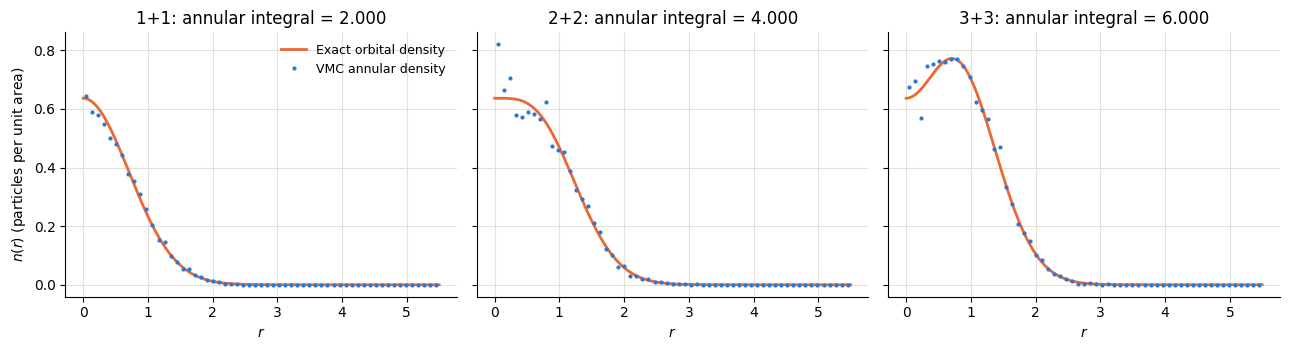

In [9]:
def radial_number_density(samples,bins):
    radii = np.linalg.norm(samples,axis=-1).ravel()
    counts,edges = np.histogram(radii,bins=bins)
    areas = np.pi*(edges[1:]**2-edges[:-1]**2)
    return 0.5*(edges[1:]+edges[:-1]),counts/(len(samples)*areas),edges


def exact_radial_density(r,n_up,n_down,n_angles=96):
    theta = 2*np.pi*np.arange(n_angles)/n_angles
    xy = np.stack([r[:,None]*np.cos(theta)[None,:]+np.zeros((len(r),n_angles)),
                   r[:,None]*np.sin(theta)[None,:]+np.zeros((len(r),n_angles))],axis=-1)
    density = np.zeros((len(r),n_angles))
    for n in (n_up,n_down):
        if n:
            phi = orbital_values(xy,occupied_orbitals(n))
            density += np.sum(phi**2,axis=-1)
    return np.mean(density,axis=1)

bins = np.linspace(0,5.5,60)
fig,axes=plt.subplots(1,3,figsize=(13,3.6),sharey=True)
for ax,(nu,nd) in zip(axes,[(1,1),(2,2),(3,3)]):
    X = runs[(nu,nd)]
    r,density,edges = radial_number_density(X,bins)
    r_fine = np.linspace(0,5.5,500)
    ax.plot(r_fine,exact_radial_density(r_fine,nu,nd),color=C_EXACT,label='Exact orbital density')
    ax.plot(r,density,'.',color=C_VMC,label='VMC annular density',markersize=4)
    integrated = np.sum(density*np.pi*(edges[1:]**2-edges[:-1]**2))
    ax.set(xlabel=r'$r$',title=f'{nu}+{nd}: annular integral = {integrated:.3f}')
    assert abs(integrated-(nu+nd)) < 0.05
axes[0].set_ylabel(r'$n(r)$ (particles per unit area)')
axes[0].legend(frameon=False,fontsize=9)
fig.tight_layout()
plt.show()

r_test = np.linspace(0,3,30)
np.testing.assert_allclose(exact_radial_density(r_test,3,3),
    (2/np.pi)*np.exp(-r_test**2)*(1+2*r_test**2),atol=1e-12)

## 10. Same-spin pair distribution and the exchange hole

For $C=\binom{N_\uparrow}{2}+\binom{N_\downarrow}{2}>0$ same-spin unordered pairs, define the **probability density of pair separation**

$$P_\mathrm{same}(d)=\frac1C\left\langle\sum_{\sigma}\sum_{i<j\in\sigma}\delta\big(d-|\mathbf r_i-\mathbf r_j|\big)\right\rangle,\qquad
\boxed{\int_0^\infty P_\mathrm{same}(d)\,dd=1.}$$

**Estimator:** concatenate all same-spin Euclidean distances across configurations and form a count histogram divided by `(n_samples * C * bin_width)`. For $1+1$, $C=0$: the same-spin distribution is **undefined**, not zero.

**A subtle 2D issue:** even a noninteracting *distinguishable* pair has $P(d)\sim d$ as $d\to0$ due to polar phase-space volume. A true Pauli hole suppresses the **area-normalized density** $P(d)/(2\pi d)$, which behaves as $d^2$ near zero for smooth same-spin fermionic states. For comparison, create a reference by **independently permuting the sample axis for each particle label**: this preserves each one-body marginal but removes within-sample exchange correlations.

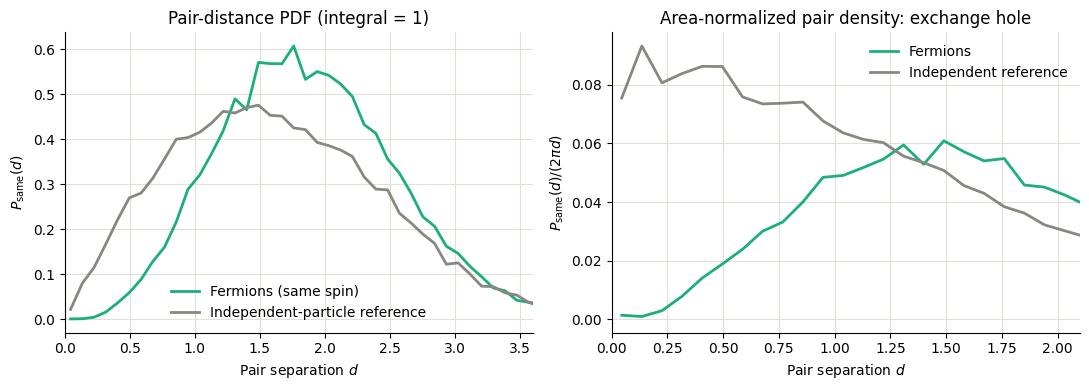

In [10]:
def same_spin_pair_distances(samples,n_up):
    """Return array (n_samples,C), C = C(n_up,2)+C(n_down,2)."""
    ns,N,_ = samples.shape
    pieces = []
    for a,b in ((0,n_up),(n_up,N)):
        i,j = np.triu_indices(b-a,k=1)
        if len(i):
            differences = samples[:,a+i,:]-samples[:,a+j,:]
            pieces.append(np.linalg.norm(differences,axis=-1))
    return np.concatenate(pieces,axis=1) if pieces else np.empty((ns,0))


def independent_reference_samples(samples,rng=rng):
    """Break pair correlations without modifying single-particle marginals."""
    ref = samples.copy()
    for i in range(samples.shape[1]):
        ref[:,i,:] = samples[rng.permutation(len(samples)),i,:]
    return ref

X = runs[(3,3)]
d_real = same_spin_pair_distances(X,3).ravel()
d_reference = same_spin_pair_distances(independent_reference_samples(X),3).ravel()
assert d_real.size == len(X)*6
edges=np.linspace(0,max(d_real.max(),d_reference.max())+1e-6,62)
counts,_=np.histogram(d_real,bins=edges)
counts_ref,_=np.histogram(d_reference,bins=edges)
centers = 0.5*(edges[1:]+edges[:-1])
widths = np.diff(edges)
P = counts/(len(X)*6*widths)
P_ref = counts_ref/(len(X)*6*widths)
assert np.isclose(np.sum(P*widths),1.0)
assert np.isclose(np.sum(P_ref*widths),1.0)

fig,(ax_pair,ax_area)=plt.subplots(1,2,figsize=(11,4))
ax_pair.plot(centers,P,color=C_FERMI,label='Fermions (same spin)')
ax_pair.plot(centers,P_ref,color=C_REF,label='Independent-particle reference')
ax_pair.set(xlabel=r'Pair separation $d$',ylabel=r'$P_{\mathrm{same}}(d)$',
            title='Pair-distance PDF (integral = 1)',xlim=(0,3.6))
ax_pair.legend(frameon=False)
ax_area.plot(centers,P/(2*np.pi*centers),color=C_FERMI,label='Fermions')
ax_area.plot(centers,P_ref/(2*np.pi*centers),color=C_REF,label='Independent reference')
ax_area.set(xlabel=r'Pair separation $d$',ylabel=r'$P_{\mathrm{same}}(d)/(2\pi d)$',
            title='Area-normalized pair density: exchange hole',xlim=(0,2.1))
ax_area.legend(frameon=False)
fig.tight_layout()
plt.show()

## 11. Final pass criteria and further questions

**Pass criteria:**

1. **Spectrum / shell filling:** $E_0(1,1)=2$, $E_0(2,2)=6$, $E_0(3,3)=10$, and optionally $E_0(6,6)=28$.
2. **Antisymmetry:** swapping two same-spin positions flips the sign of the total wavefunction but leaves $\log|\Psi|$ and $|\Psi|^2$ unchanged to machine precision.
3. **Local energy:** $E_L(X)=E_0$ pointwise off nodes and the VMC mean agrees within MC error / floating-point tolerance; AD and analytic orbital derivatives agree for at least one test.
4. **Density normalization:** $2\pi\int r n(r)dr=N$ (allow small finite-bin/tail error) and agree with exact angularly averaged orbital density.
5. **Pair distribution:** normalized $\int P_\mathrm{same}(d)dd=1$ for $C>0$, and demonstrable suppression of the area-normalized near-zero pair density versus the decorrelated reference.

**Further questions:** How does a partially filled shell break rotational symmetry? Why can Metropolis cross a nodal surface even though its stationary density vanishes on the surface? How would a symmetric Jastrow factor change pair correlations while preserving same-spin antisymmetry? Which formulas change when interactions are added?

**Reading:** Bayha et al., *Nature* **587**, 583–587 (2020), DOI `10.1038/s41586-020-2936-y`; Foulkes et al., *Rev. Mod. Phys.* **73**, 33 (2001), Slater determinants and VMC.